# E-Commerce Sales & Customer Analysis (Google Colab version)

A beginner-friendly data analysis of the **UCI Online Retail** dataset (Dec 2010 – Dec 2011) using Python, pandas, Matplotlib and Seaborn.

**How to run in Colab:** click `Runtime → Run all`. When the setup cell asks for a file, upload **Online Retail.xlsx** (or the zip that contains it). Reading the Excel file takes a minute or two.

| Part | What it covers |
|---|---|
| 1 | Data cleaning |
| 2 | Sales analysis |
| 3 | Customer analysis |

In [1]:
# ---- Setup: creates folders and gets the dataset (works in Google Colab and on your own computer) ----
import os
import zipfile
import shutil

try:
    from google.colab import files
    in_colab = True
except ImportError:
    in_colab = False

project = "/content/project" if in_colab else os.path.abspath("..")
for folder in ["notebooks", "data", "images"]:
    os.makedirs(project + "/" + folder, exist_ok=True)
os.chdir(project + "/notebooks")          # the code below uses paths like ../data

excel_path = project + "/data/Online Retail.xlsx"
if not os.path.exists(excel_path):
    if not in_colab:
        raise FileNotFoundError("Put 'Online Retail.xlsx' in the data folder: " + project + "/data/")
    print("Upload 'Online Retail.xlsx' (or the .zip that contains it):")
    uploaded = files.upload()
    for name in uploaded:
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(name) as z:
                z.extractall(project + "/data")
        elif name.lower().endswith(".xlsx"):
            shutil.move(name, excel_path)
    if not os.path.exists(excel_path):        # the zip may contain a differently named file
        for f in os.listdir(project + "/data"):
            if f.lower().endswith(".xlsx"):
                os.rename(project + "/data/" + f, excel_path)
print("Dataset found:", os.path.exists(excel_path))

Dataset found: True


---
# Part 1

# 01 · Data Cleaning

**Dataset:** UCI *Online Retail*: every transaction of a UK online gift-ware shop from 1 Dec 2010 to 9 Dec 2011. Many of the customers are wholesalers.

**Goal of this part:** check the raw data for problems, fix them step by step, and save two clean files (`sales_clean.csv` and `returns_clean.csv`) for the analysis parts.

**Steps**
1. Look at the data
2. Check missing values
3. Remove duplicates
4. Separate cancelled orders (returns)
5. Remove rows that are not products
6. Remove invalid prices and quantities
7. Check suspicious very large orders
8. Create new columns (Revenue, month, weekday, hour)
9. Save the clean data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [3]:
df_raw = pd.read_excel("../data/Online Retail.xlsx")
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. First look at the data

In [4]:
print("Rows and columns:", df_raw.shape)
df_raw.info()

Rows and columns: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
df_raw.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


**What the output means:** there are about 540,000 rows and 8 columns. `describe()` shows that `Quantity` and `UnitPrice` contain **negative or zero values**, which cannot be normal sales. These need to be investigated.

**Business decision:** before we can trust any revenue number, the data must be cleaned. Wrong rows would give a wrong picture of the business.

## 2. Missing values

**Business question:** can we link every sale to a customer?

In [6]:
print(df_raw.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [7]:
missing_customer_percent = df_raw["CustomerID"].isnull().sum() / len(df_raw) * 100
print("Rows without CustomerID (%):", round(missing_customer_percent, 1))

Rows without CustomerID (%): 24.9


**What the output means:** about a quarter of the rows have no `CustomerID` (probably guest checkouts). `Description` is also missing in a small number of rows.

**Business decision:** these are real sales, so we **keep** them for sales analysis (revenue, products, countries). We cannot use them for customer analysis, so in Part 3 we will drop them. The shop should also try to capture a customer ID at checkout.

## 3. Duplicate rows

In [8]:
print("Duplicate rows:", df_raw.duplicated().sum())

Duplicate rows: 5268


In [9]:
df = df_raw.copy()                       # work on a copy, keep the raw data safe
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)

print("Rows at the start:", len(df))
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows at the start: 541909
Rows after removing duplicates: 536641


**What the output means:** about 5,000 rows were exact copies of another row.

**Business decision:** duplicates would count the same sale twice and inflate revenue, so we remove them.

## 4. Remove rows that are not products

**Business question:** are all rows real product sales?

In [10]:
service_codes = ["POST", "DOT", "M", "m", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS", "B"]
df[df["StockCode"].isin(service_codes)]["StockCode"].value_counts()

,count
StockCode,
POST,1256
DOT,710
M,566
C2,144
D,77
S,62
BANK CHARGES,37
AMAZONFEE,34
CRUK,16


**What the output means:** codes like `POST` (postage), `DOT` (dotcom postage), `M` (manual entry), `BANK CHARGES` and `AMAZONFEE` are fees and services, not products.

**Business decision:** if we leave them in, they would appear as "products" in the top-products chart. We remove them (the `~` sign means NOT).

In [11]:
df = df[~df["StockCode"].isin(service_codes)]
print("Rows after removing non-product rows:", len(df))

Rows after removing non-product rows: 533731


## 5. Cancelled orders (returns)

Invoice numbers that start with the letter **C** are cancellations.

In [12]:
is_cancelled = df["InvoiceNo"].str.startswith("C")
print("Cancelled rows:", is_cancelled.sum())
df[is_cancelled].head()

Cancelled rows: 8668


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


**What the output means:** cancelled rows have a **negative Quantity**. If we add them to sales, they would reduce revenue and hide how many returns there are.

**Business decision:** we split the data into two tables, `sales` and `returns`. That lets us measure sales and returns separately.

In [13]:
returns = df[is_cancelled].copy()
sales = df[~is_cancelled].copy()
print("Sales rows:", len(sales))
print("Return rows:", len(returns))

Sales rows: 525063
Return rows: 8668


## 6. Invalid quantities and prices

In [14]:
print("Sales rows with Quantity <= 0:", (sales["Quantity"] <= 0).sum())
print("Sales rows with UnitPrice <= 0:", (sales["UnitPrice"] <= 0).sum())

Sales rows with Quantity <= 0: 1336
Sales rows with UnitPrice <= 0: 2495


In [15]:
sales = sales[(sales["Quantity"] > 0) & (sales["UnitPrice"] > 0)]
print("Sales rows after removing invalid rows:", len(sales))

Sales rows after removing invalid rows: 522568


**What the output means:** a few thousand rows have zero price or negative quantity (stock adjustments, damaged goods, free items). They are not real sales.

**Business decision:** we keep only rows where both Quantity and UnitPrice are above zero.

## 7. Create the Revenue column and check the largest orders

In [16]:
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales.sort_values("Revenue", ascending=False).head(5)[["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID", "Revenue"]]

,InvoiceNo,Description,Quantity,UnitPrice,CustomerID,Revenue
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,168469.60
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,77183.60
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098.0,38970.00
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,17450.0,7144.72
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,6539.40


The top three orders are very large (£168K, £77K and £39K). Real orders this size would be rare, so let's check if they were cancelled.

In [17]:
suspicious = ["541431", "C541433", "581483", "C581484", "556444", "C556445"]
df_raw[df_raw["InvoiceNo"].astype(str).isin(suspicious)][["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate"]]

,InvoiceNo,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,2011-01-18 10:17:00
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098.0,2011-06-10 15:28:00
222681,C556445,Manual,-1,38970.00,15098.0,2011-06-10 15:31:00
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,2011-12-09 09:27:00


**What the output means:** each huge order was **cancelled by the same customer a few minutes later** (the cancellation has a negative quantity and an invoice number starting with C). These look like data-entry mistakes.

**Business decision:** keeping them would add about £284K of revenue that never really happened (nearly 3% of total revenue) and would distort every average. We remove the three orders and their cancellations.

In [18]:
sales = sales[~sales["InvoiceNo"].isin(["541431", "581483", "556444"])]
returns = returns[~returns["InvoiceNo"].isin(["C541433", "C581484"])]
print("Final sales rows:", len(sales))
print("Final return rows:", len(returns))

Final sales rows: 522565
Final return rows: 8666


## 8. Create new columns for analysis
We extract the month, weekday and hour from the invoice date. These will be used to see patterns over time.

In [19]:
sales["YearMonth"] = sales["InvoiceDate"].dt.strftime("%Y-%m")
sales["Weekday"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

returns["ReturnValue"] = returns["Quantity"].abs() * returns["UnitPrice"]
returns["YearMonth"] = returns["InvoiceDate"].dt.strftime("%Y-%m")

sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth,Weekday,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday,8


## 9. Final checks

In [20]:
print("First date:", sales["InvoiceDate"].min())
print("Last date :", sales["InvoiceDate"].max())
print("Total revenue (£):", round(sales["Revenue"].sum()))
print("Number of orders:", sales["InvoiceNo"].nunique())
print("Smallest Quantity:", sales["Quantity"].min(), "| Smallest UnitPrice:", sales["UnitPrice"].min())

First date: 2010-12-01 08:26:00
Last date : 2011-12-09 12:50:00
Total revenue (£): 9963282
Number of orders: 19770
Smallest Quantity: 1 | Smallest UnitPrice: 0.04


**What the output means:** all quantities and prices are now positive. The last date is **9 December 2011**, so **December 2011 is only a partial month** and must not be compared directly with full months.

**Business decision:** in later notebooks we will mention this whenever December 2011 appears, so nobody wrongly concludes that "sales crashed in December".

## 10. Save the clean data

In [21]:
sales.to_csv("../data/sales_clean.csv", index=False)
returns.to_csv("../data/returns_clean.csv", index=False)
print("Saved sales_clean.csv and returns_clean.csv")

Saved sales_clean.csv and returns_clean.csv


## Summary of cleaning

| Step | What we did | Why |
|---|---|---|
| Duplicates | Removed exact copies | Avoid counting a sale twice |
| Non-product codes | Removed postage, fees, manual entries | Keep product analysis honest |
| Cancellations | Moved to a separate `returns` table | Measure returns separately |
| Invalid rows | Removed Quantity ≤ 0 or UnitPrice ≤ 0 | Not real sales |
| Mega-orders | Removed 3 orders cancelled within minutes | Data-entry errors inflated revenue |
| Missing CustomerID | Kept for sales, excluded in customer analysis | Still real revenue |

---
# Part 2

# 02 · Sales Analysis

In this part we answer practical questions about the shop's sales. Each section has the same structure:
**Business question → Code → What the output means → Business decision.**

All money is in British pounds (£). Remember from Part 1: **December 2011 is only a partial month** (data ends on 9 Dec).

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

sales = pd.read_csv("../data/sales_clean.csv", parse_dates=["InvoiceDate"])
returns = pd.read_csv("../data/returns_clean.csv", parse_dates=["InvoiceDate"])
print("Sales rows:", len(sales), "| Return rows:", len(returns))

Sales rows: 522565 | Return rows: 8666


## 1. Key numbers

**Business question:** how big is the business, and what does a typical order look like?

In [23]:
total_revenue = sales["Revenue"].sum()
total_orders = sales["InvoiceNo"].nunique()
total_customers = sales["CustomerID"].nunique()
average_order_value = total_revenue / total_orders

order_value = sales.groupby("InvoiceNo")["Revenue"].sum()      # revenue of each order
median_order_value = order_value.median()

revenue_without_customer = sales[sales["CustomerID"].isnull()]["Revenue"].sum()

print("Total revenue (£):", round(total_revenue))
print("Number of orders:", total_orders)
print("Number of customers:", total_customers)
print("Average order value (£):", round(average_order_value))
print("Median order value (£):", round(median_order_value))
print("Revenue from orders without CustomerID (%):", round(revenue_without_customer / total_revenue * 100, 1))

Total revenue (£): 9963282
Number of orders: 19770
Number of customers: 4333
Average order value (£): 504
Median order value (£): 302
Revenue from orders without CustomerID (%): 15.2


**What the output means:** the shop made about **£9.96 million** from **19,770 orders** and 4,333 identified customers. The *average* order is about £504 but the *median* order is only about £302, which means a few very large orders pull the average up. About 15% of revenue comes from orders with no customer ID.

**Business decision:** when describing a "typical" order, use the **median (£302)**, not the average. And because 15% of revenue cannot be linked to a customer, the shop should ask for an email or customer ID at checkout.

## 2. Monthly revenue

**Business question:** how does revenue change through the year, and is there a busy season?

In [24]:
monthly_revenue = sales.groupby("YearMonth")["Revenue"].sum()
monthly_revenue

,Revenue
YearMonth,
2010-12,775714.95
2011-01,593255.86
2011-02,507866.54
2011-03,689841.84
2011-04,515469.66
2011-05,740036.33
2011-06,698713.99
2011-07,688252.67
2011-08,724308.16


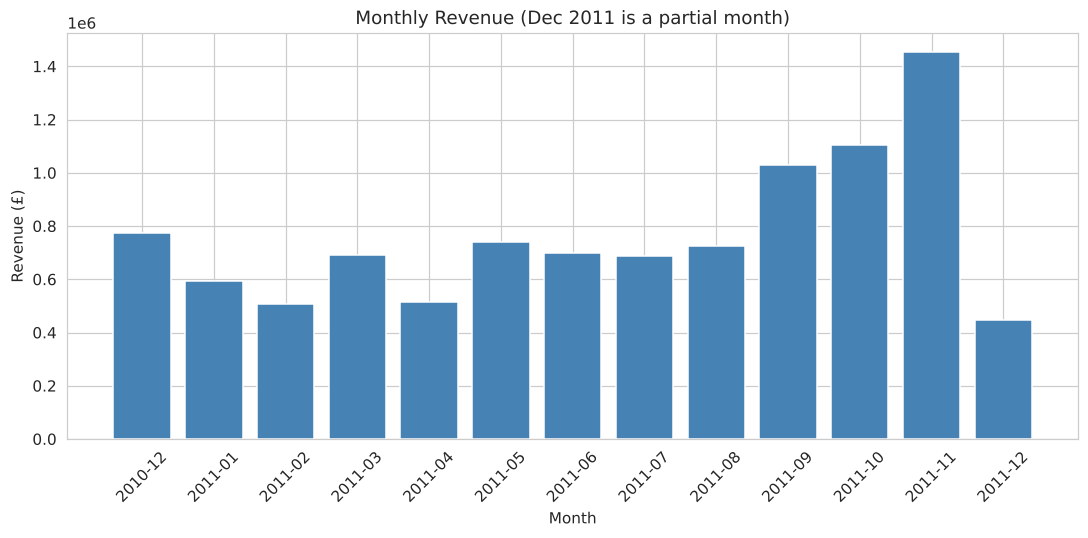

In [25]:
plt.figure(figsize=(10, 5))
plt.bar(monthly_revenue.index, monthly_revenue.values, color="steelblue")
plt.title("Monthly Revenue (Dec 2011 is a partial month)")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/01_monthly_revenue.png", dpi=150)
plt.show()

In [26]:
jan_to_aug_average = monthly_revenue.loc["2011-01":"2011-08"].mean()
november_revenue = monthly_revenue.loc["2011-11"]
print("Average month Jan-Aug 2011 (£):", round(jan_to_aug_average))
print("November 2011 (£):", round(november_revenue))
print("November is", round(november_revenue / jan_to_aug_average, 1), "times the Jan-Aug average")

Average month Jan-Aug 2011 (£): 644718
November 2011 (£): 1452116
November is 2.3 times the Jan-Aug average


**What the output means:** from January to August revenue stays between about £510K and £740K per month. Then it jumps: **September £1.03M, October £1.10M and November £1.45M**, which is about 2.3 times the Jan–Aug average. (December 2011 looks low only because the data stops on 9 December.)

**Business decision:** the busy season starts in **September**, not December. Stock, packing staff and delivery capacity should be ready by late August. The weakest months are February and April, so those are good months to **test promotions** that could even out sales across the year.

## 3. Month-over-month growth

**Business question:** is revenue growing steadily, or is it up and down?

In [27]:
# Leave out Dec 2011 because it is only a partial month
monthly_full = monthly_revenue.drop("2011-12")

# pct_change() compares each month with the month before it
monthly_growth = monthly_full.pct_change() * 100
monthly_growth.round(1)

,Revenue
YearMonth,
2010-12,NaN
2011-01,-23.5
2011-02,-14.4
2011-03,35.8
2011-04,-25.3
2011-05,43.6
2011-06,-5.6
2011-07,-1.5
2011-08,5.2


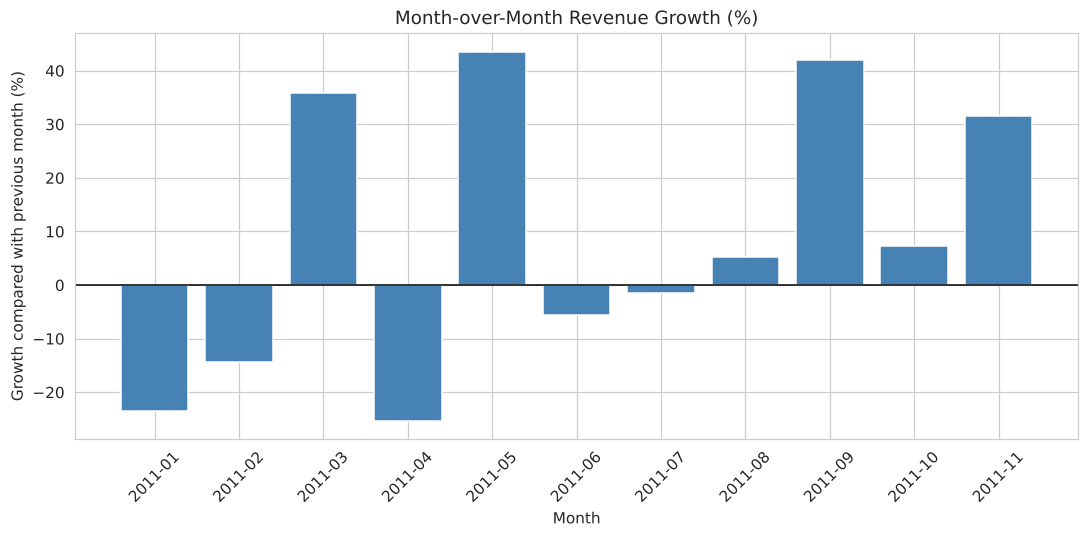

In [28]:
plt.figure(figsize=(10, 5))
plt.bar(monthly_growth.index, monthly_growth.values, color="steelblue")
plt.axhline(0, color="black", linewidth=1)
plt.title("Month-over-Month Revenue Growth (%)")
plt.xlabel("Month")
plt.ylabel("Growth compared with previous month (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/02_monthly_growth.png", dpi=150)
plt.show()

In [29]:
print("Months with growth:", (monthly_growth > 0).sum(), "out of", monthly_growth.count())

Months with growth: 6 out of 11


**What the output means:** growth is very uneven. Revenue fell in January (-24%), February (-14%) and April (-25%) and jumped in March (+36%) and May (+44%). Only **6 of 11 months grew**. The strongest growth is in the autumn: September +42%, October +7%, November +32%.

**Business decision:** do not judge performance from a single month. With only one year of data we **cannot say whether the autumn jump is real growth or just seasonality**. The shop should compare each month with the *same month next year* before making big investment decisions.

## 4. What drives the autumn growth: more orders or bigger orders?

**Business question:** revenue = number of orders × average order value. Which one grew in autumn?

In [30]:
orders_per_month = sales.groupby("YearMonth")["InvoiceNo"].nunique().drop("2011-12")
avg_order_value_per_month = monthly_full / orders_per_month

print("Orders per month:")
print(orders_per_month)
print()
print("Average order value per month (£):")
print(avg_order_value_per_month.round(0))

Orders per month:
YearMonth
2010-12    1550
2011-01    1080
2011-02    1093
2011-03    1440
2011-04    1235
2011-05    1668
2011-06    1524
2011-07    1452
2011-08    1339
2011-09    1818
2011-10    2005
2011-11    2751
Name: InvoiceNo, dtype: int64

Average order value per month (£):
YearMonth
2010-12    500.0
2011-01    549.0
2011-02    465.0
2011-03    479.0
2011-04    417.0
2011-05    444.0
2011-06    458.0
2011-07    474.0
2011-08    541.0
2011-09    566.0
2011-10    550.0
2011-11    528.0
dtype: float64


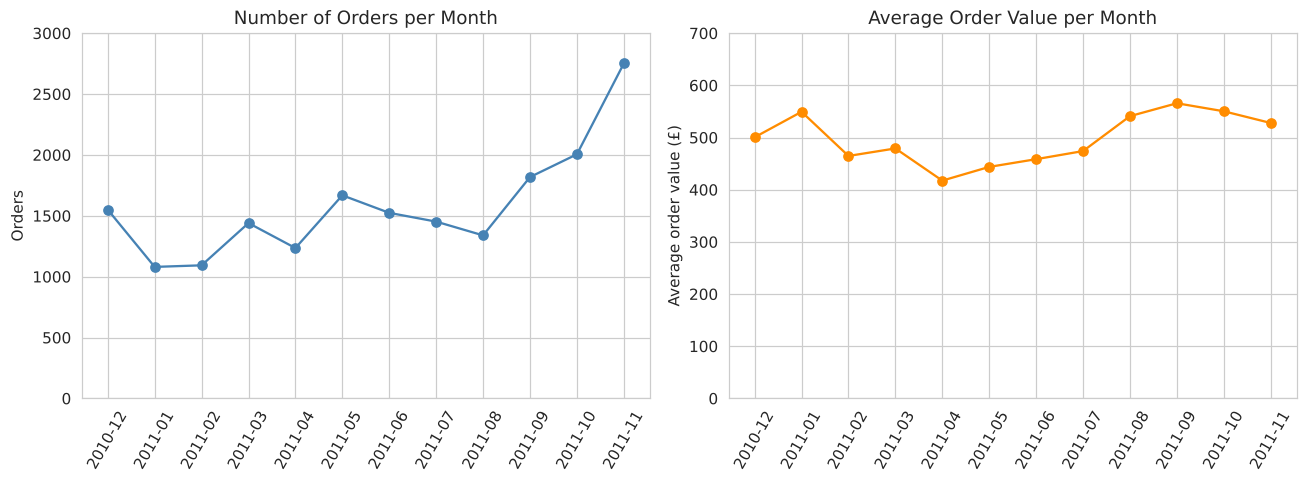

In [31]:
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(orders_per_month.index, orders_per_month.values, marker="o", color="steelblue")
plt.title("Number of Orders per Month")
plt.ylabel("Orders")
plt.ylim(0, 3000)
plt.xticks(rotation=60)

plt.subplot(1, 2, 2)
plt.plot(avg_order_value_per_month.index, avg_order_value_per_month.values, marker="o", color="darkorange")
plt.title("Average Order Value per Month")
plt.ylabel("Average order value (£)")
plt.ylim(0, 700)
plt.xticks(rotation=60)

plt.tight_layout()
plt.savefig("../images/03_orders_and_aov.png", dpi=150)
plt.show()

In [32]:
jan_to_aug_orders = orders_per_month.loc["2011-01":"2011-08"].mean()
print("November orders vs Jan-Aug average:", round(orders_per_month.loc["2011-11"] / jan_to_aug_orders, 1), "times")

November orders vs Jan-Aug average: 2.0 times


**What the output means:** the number of orders in November (2,751) is about **2 times** the Jan–Aug average, while the average order value stays in a narrow range of roughly £420–£570 all year. So the autumn growth comes mainly from **more orders**, not from bigger orders.

**Business decision:** the shop needs **capacity** (staff, packing, delivery, customer service) for about double the orders in autumn. A second idea to test is raising the order value, for example with bundles or a "free delivery above £X" offer, because order value has not grown during the busy season.

## 5. Top products

**Business question:** which products bring the most revenue, and which sell the most units?

In [33]:
revenue_by_product = sales.groupby("Description")["Revenue"].sum().sort_values(ascending=False)
top_10_revenue = revenue_by_product.head(10)

units_by_product = sales.groupby("Description")["Quantity"].sum().sort_values(ascending=False)
top_10_units = units_by_product.head(10)

top_10_revenue

,Revenue
Description,
REGENCY CAKESTAND 3 TIER,174156.54
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
RABBIT NIGHT LIGHT,66870.03
PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
ASSORTED COLOUR BIRD ORNAMENT,58927.62
CHILLI LIGHTS,54096.36
SPOTTY BUNTING,42513.48


In [34]:
top_10_units

,Quantity
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48371
WHITE HANGING HEART T-LIGHT HOLDER,37872
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739
MINI PAINT SET VINTAGE,26633
PACK OF 12 LONDON TISSUES,26119


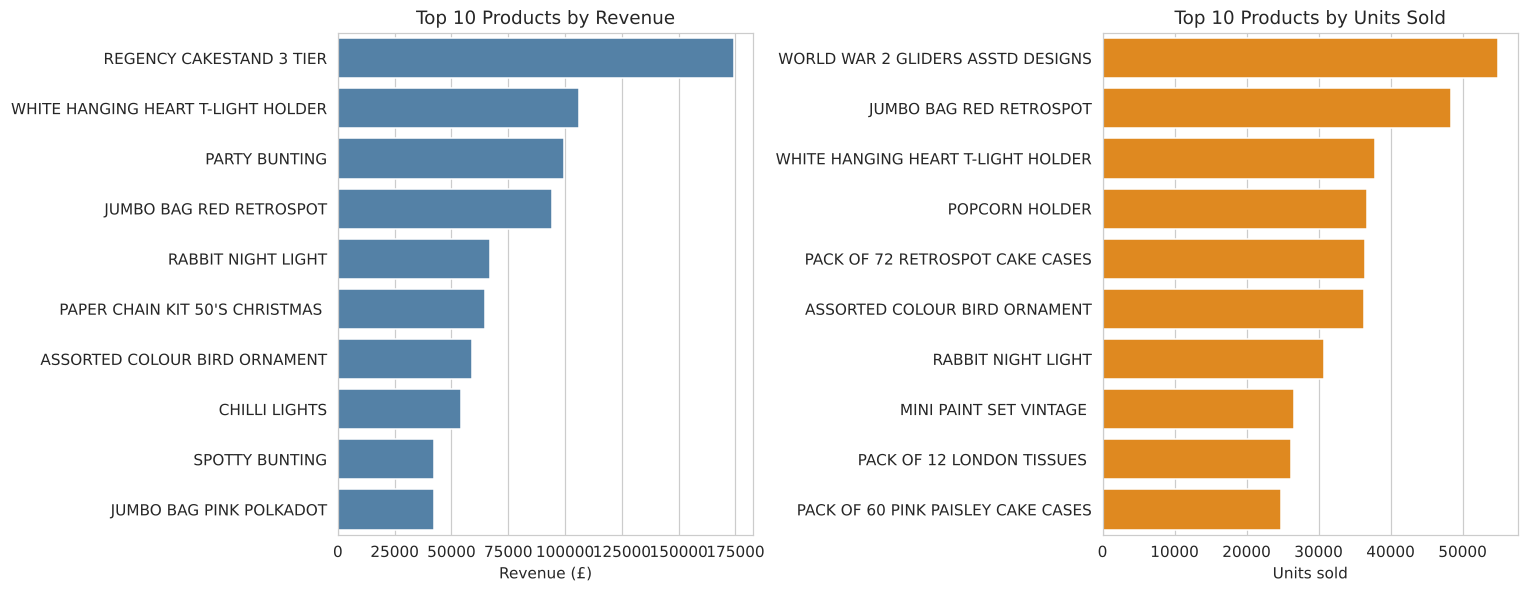

In [35]:
plt.figure(figsize=(14, 5.5))

plt.subplot(1, 2, 1)
sns.barplot(x=top_10_revenue.values, y=top_10_revenue.index, color="steelblue")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("")

plt.subplot(1, 2, 2)
sns.barplot(x=top_10_units.values, y=top_10_units.index, color="darkorange")
plt.title("Top 10 Products by Units Sold")
plt.xlabel("Units sold")
plt.ylabel("")

plt.tight_layout()
plt.savefig("../images/04_top_products.png", dpi=150)
plt.show()

**What the output means:** the best product by revenue is the **Regency Cakestand 3 Tier** (about £174K), well ahead of the White Hanging Heart T-Light Holder (about £106K). The two lists are different: the Regency Cakestand is #1 by revenue but not in the top 10 by units because it is an expensive item, while **World War 2 Gliders** is #1 by units but not in the top 10 by revenue because it is cheap.

**Business decision:** use the **revenue** list to decide where to put marketing effort and stock money, and the **units** list to plan warehouse space and packing work. Never rank products by units alone.

## 6. Which products sell in autumn?

**Business question:** do the best sellers change between the quiet months (Jan–Aug) and the busy months (Sep–Nov)?

In [36]:
# Boolean filtering with dates
autumn = sales[(sales["InvoiceDate"] >= "2011-09-01") & (sales["InvoiceDate"] < "2011-12-01")]
jan_to_aug = sales[(sales["InvoiceDate"] >= "2011-01-01") & (sales["InvoiceDate"] < "2011-09-01")]

top_autumn = autumn.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
top_jan_to_aug = jan_to_aug.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)

print("Top 10 products in Sep-Nov 2011:")
print(top_autumn.round(0))
print()
print("Top 10 products in Jan-Aug 2011:")
print(top_jan_to_aug.round(0))

Top 10 products in Sep-Nov 2011:
Description
RABBIT NIGHT LIGHT                    47435.0
PAPER CHAIN KIT 50'S CHRISTMAS        44975.0
REGENCY CAKESTAND 3 TIER              36649.0
JUMBO BAG RED RETROSPOT               31005.0
WHITE HANGING HEART T-LIGHT HOLDER    26304.0
HOT WATER BOTTLE KEEP CALM            24151.0
POPCORN HOLDER                        22494.0
PAPER CHAIN KIT VINTAGE CHRISTMAS     22256.0
DOORMAT KEEP CALM AND COME IN         21580.0
HOT WATER BOTTLE TEA AND SYMPATHY     20668.0
Name: Revenue, dtype: float64

Top 10 products in Jan-Aug 2011:
Description
REGENCY CAKESTAND 3 TIER              103818.0
PARTY BUNTING                          82479.0
WHITE HANGING HEART T-LIGHT HOLDER     66492.0
JUMBO BAG RED RETROSPOT                56908.0
ASSORTED COLOUR BIRD ORNAMENT          34758.0
SPOTTY BUNTING                         29068.0
JUMBO BAG PINK POLKADOT                25558.0
CHILLI LIGHTS                          24109.0
LUNCH BAG RED RETROSPOT                2363

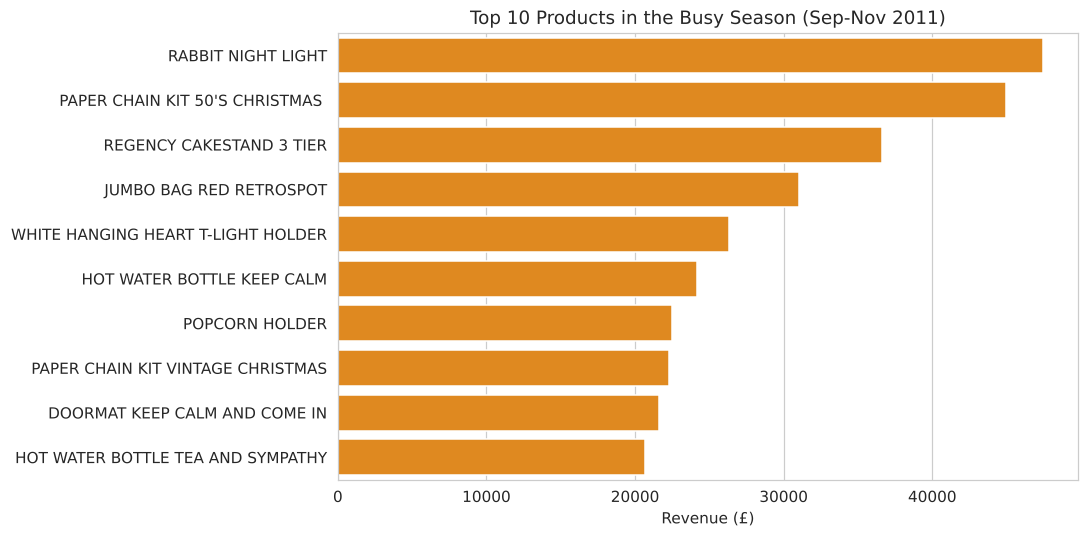

In [37]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_autumn.values, y=top_autumn.index, color="darkorange")
plt.title("Top 10 Products in the Busy Season (Sep-Nov 2011)")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/05_autumn_top_products.png", dpi=150)
plt.show()

In [38]:
sep_to_nov_revenue = autumn["Revenue"].sum()
jan_to_nov_revenue = sales[(sales["InvoiceDate"] >= "2011-01-01") & (sales["InvoiceDate"] < "2011-12-01")]["Revenue"].sum()
print("Sep-Nov share of Jan-Nov revenue (%):", round(sep_to_nov_revenue / jan_to_nov_revenue * 100))

Sep-Nov share of Jan-Nov revenue (%): 41


**What the output means:** in Sep–Nov, winter and Christmas items move to the top: **Rabbit Night Light, Paper Chain Kits (Christmas), Hot Water Bottles** and the Keep Calm Doormat. In Jan–Aug the leaders are party and kitchen items such as the Regency Cakestand, Party Bunting and Jumbo Bags. Sep–Nov alone brings about **41% of the Jan–Nov revenue**.

**Business decision:** order winter and Christmas products **before September** so they are never out of stock in the busiest months, and focus spring and summer marketing on party, kitchen and bag products.

## 7. Countries

**Business question:** where do sales come from, and which export countries matter?

In [39]:
revenue_by_country = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = revenue_by_country.loc["United Kingdom"] / revenue_by_country.sum() * 100
print("UK share of revenue (%):", round(uk_share, 1))

export_revenue = revenue_by_country.drop("United Kingdom")      # everything except the UK
top_export = export_revenue.head(10)
top_export.round(0)

UK share of revenue (%): 84.7


,Revenue
Country,
Netherlands,283889.0
EIRE,270851.0
Germany,205381.0
France,184493.0
Australia,138104.0
Spain,55707.0
Switzerland,53066.0
Japan,37416.0
Belgium,36927.0


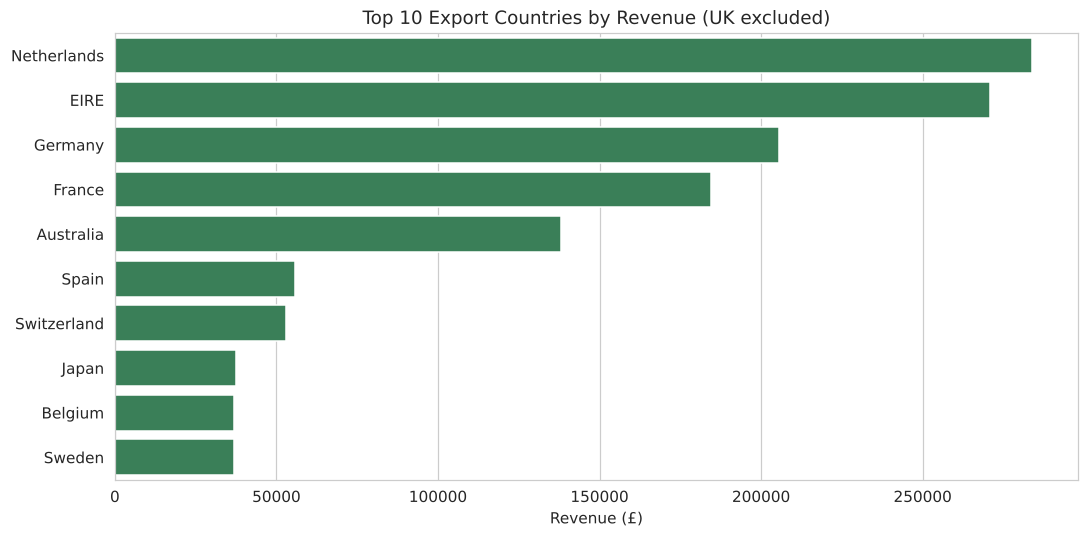

In [40]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_export.values, y=top_export.index, color="seagreen")
plt.title("Top 10 Export Countries by Revenue (UK excluded)")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/06_export_countries.png", dpi=150)
plt.show()

In [41]:
# How many different customers are behind the top 5 export countries?
export_sales = sales[sales["Country"] != "United Kingdom"]
customers_per_country = export_sales.groupby("Country")["CustomerID"].nunique()
print(customers_per_country.loc[top_export.head(5).index])

Country
Netherlands     9
EIRE            3
Germany        94
France         87
Australia       9
Name: CustomerID, dtype: int64


In [42]:
uk_order_value = sales[sales["Country"] == "United Kingdom"].groupby("InvoiceNo")["Revenue"].sum()
export_order_value = export_sales.groupby("InvoiceNo")["Revenue"].sum()
print("Average order value UK (£):", round(uk_order_value.mean()))
print("Average order value export (£):", round(export_order_value.mean()))

Average order value UK (£): 472
Average order value export (£): 813


**What the output means:** the **UK is about 85% of all revenue**. The top export markets are the Netherlands, EIRE (Ireland), Germany, France and Australia. Export orders are bigger (about £813 vs £472 in the UK). The customer counts show an important detail: the Netherlands, EIRE and Australia each have only **3–9 customers**, so their revenue comes from a few big wholesale buyers, while Germany and France have about 90 customers each.

**Business decision:** assign account managers to the few large export customers because losing one would hurt, and treat Germany and France as the most promising markets to grow since they have many customers. Also, the heavy dependence on the UK is a risk worth reducing over time.

## 8. When do customers buy? (weekday and hour)

**Business question:** which days and hours are the busiest?

In [43]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_revenue = sales.groupby("Weekday")["Revenue"].sum()
weekday_revenue = weekday_revenue.reindex(weekday_order).fillna(0)     # Saturday has no sales in the data -> 0
weekday_share = weekday_revenue / weekday_revenue.sum() * 100
weekday_share.round(1)

,Revenue
Weekday,
Monday,16.9
Tuesday,20.2
Wednesday,17.9
Thursday,21.4
Friday,15.7
Saturday,0.0
Sunday,8.0


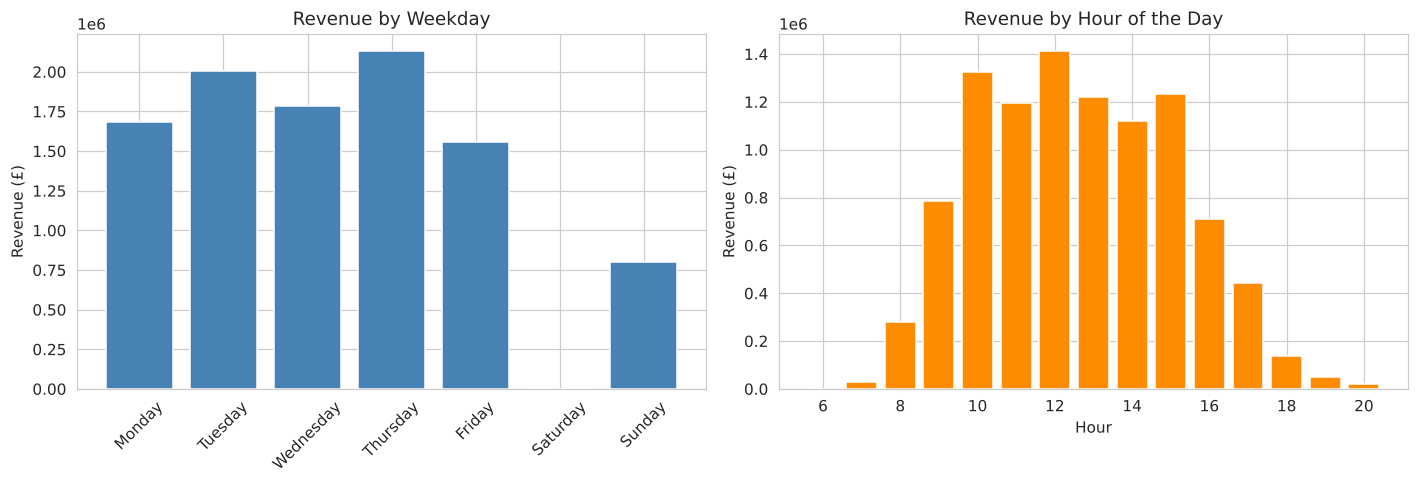

In [44]:
hourly_revenue = sales.groupby("Hour")["Revenue"].sum()

plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
plt.bar(weekday_revenue.index, weekday_revenue.values, color="steelblue")
plt.title("Revenue by Weekday")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
plt.bar(hourly_revenue.index, hourly_revenue.values, color="darkorange")
plt.title("Revenue by Hour of the Day")
plt.xlabel("Hour")
plt.ylabel("Revenue (£)")

plt.tight_layout()
plt.savefig("../images/07_weekday_and_hour.png", dpi=150)
plt.show()

In [45]:
print("Busiest hour:", hourly_revenue.idxmax())
print("Share of revenue between 10:00 and 15:59 (%):", round(hourly_revenue.loc[10:15].sum() / hourly_revenue.sum() * 100))

Busiest hour: 12
Share of revenue between 10:00 and 15:59 (%): 75


**What the output means:** **Thursday (21%) and Tuesday (20%)** are the strongest days, Sunday is the weakest (8%), and there are **no Saturday orders** in this dataset. About **75% of revenue** arrives between 10:00 and 15:59, with the peak at 12:00. This pattern (weekday working hours) is typical of business customers.

**Business decision:** have the most staff and the best website/server readiness on Tuesdays and Thursdays around midday, and send marketing emails early on those days so they arrive before the buying peak. The missing Saturday sales should be checked with the shop (is the shop closed, or is it a data problem?).

## 9. Order value

**Business question:** how large are most orders?

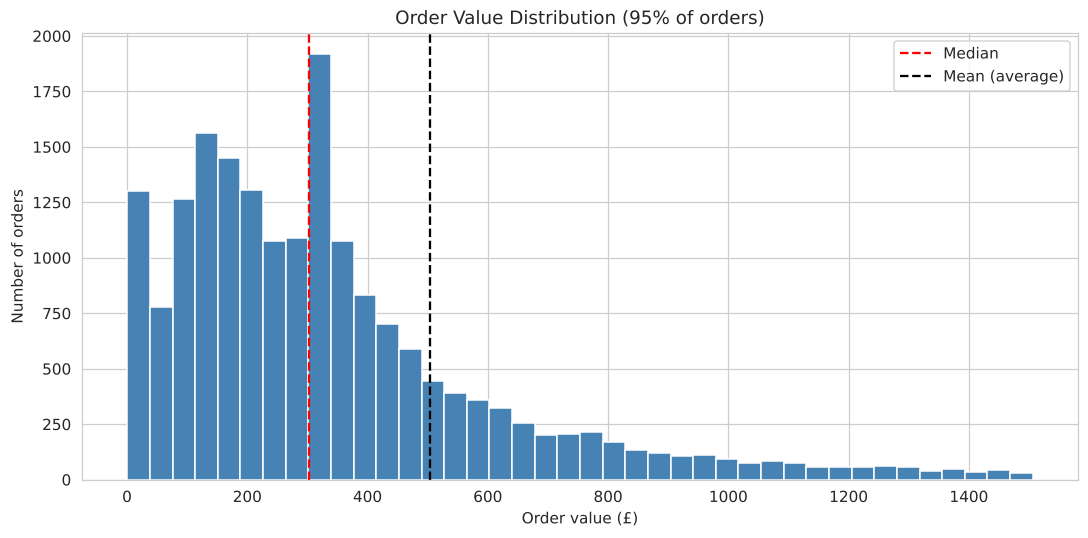

In [46]:
# Show orders up to the 95th percentile so a few giant orders do not squash the chart
limit = order_value.quantile(0.95)
normal_orders = order_value[order_value <= limit]

plt.figure(figsize=(10, 5))
plt.hist(normal_orders, bins=40, color="steelblue", edgecolor="white")
plt.axvline(order_value.median(), color="red", linestyle="--", label="Median")
plt.axvline(order_value.mean(), color="black", linestyle="--", label="Mean (average)")
plt.title("Order Value Distribution (95% of orders)")
plt.xlabel("Order value (£)")
plt.ylabel("Number of orders")
plt.legend()
plt.tight_layout()
plt.savefig("../images/08_order_value.png", dpi=150)
plt.show()

In [47]:
print("Median order (£):", round(order_value.median()))
print("Mean order (£):", round(order_value.mean()))
print("95% of orders are below (£):", round(limit))
print("Orders above £1,000:", (order_value > 1000).sum())

Median order (£): 302
Mean order (£): 504
95% of orders are below (£): 1506
Orders above £1,000: 1739


**What the output means:** most orders are small. The histogram has a long tail to the right: the median is £302 but the mean is £504 because a minority of big wholesale orders pull the average up. 95% of orders are below about £1,500.

**Business decision:** test a **free-delivery or discount threshold slightly above the typical order** (for example £350–£400) to encourage customers to add one more item. The result can be measured by checking whether the median order value rises.

## 10. Returns

**Business question:** how much money is lost to returns, and which products are returned most?

In [48]:
total_returns = returns["ReturnValue"].sum()
print("Total returns (£):", round(total_returns))
print("Returns as % of sales:", round(total_returns / total_revenue * 100, 1))

top_returned = returns.groupby("Description")["ReturnValue"].sum().sort_values(ascending=False).head(5)
top_returned.round(0)

Total returns (£): 230248
Returns as % of sales: 2.3


,ReturnValue
Description,
REGENCY CAKESTAND 3 TIER,9697.0
WHITE HANGING HEART T-LIGHT HOLDER,6624.0
FAIRY CAKE FLANNEL ASSORTED COLOUR,6591.0
PANTRY CHOPPING BOARD,4803.0
DOORMAT FAIRY CAKE,4555.0


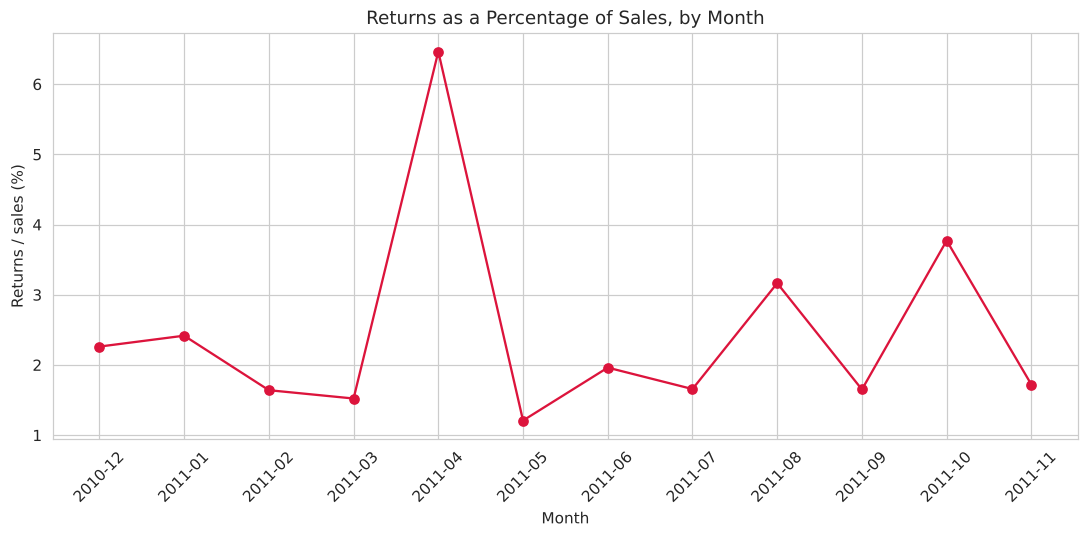

In [49]:
returns_per_month = returns.groupby("YearMonth")["ReturnValue"].sum()
return_rate = (returns_per_month / monthly_revenue * 100).drop("2011-12")

plt.figure(figsize=(10, 5))
plt.plot(return_rate.index, return_rate.values, marker="o", color="crimson")
plt.title("Returns as a Percentage of Sales, by Month")
plt.xlabel("Month")
plt.ylabel("Returns / sales (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/09_return_rate.png", dpi=150)
plt.show()

In [50]:
return_rate.round(1)

,0
YearMonth,
2010-12,2.3
2011-01,2.4
2011-02,1.6
2011-03,1.5
2011-04,6.5
2011-05,1.2
2011-06,2.0
2011-07,1.7
2011-08,3.2


**What the output means:** returns are only about **2.3% of sales value** (£230K). Most months are between 1% and 4%, but **April 2011 reached 6.5%**. The most-returned products (Regency Cakestand, White Hanging Heart Holder) are also the best sellers, so high return value does not automatically mean a quality problem.

**Business decision:** returns are not a big problem overall. The shop should check what caused the April spike (a single large cancellation made up most of it) and track the **return rate per product** (returns divided by sales of that product) to find items that are genuinely problematic.

## Key takeaways
1. Revenue is about **£9.96M**; a typical (median) order is about **£302**.
2. The busy season starts in **September**, and November is about 2.3× an average spring/summer month. Plan stock and staff before it.
3. The autumn growth comes from **more orders**, not bigger orders.
4. **Winter and Christmas products** lead in autumn; stock them early.
5. The **UK is 85%** of revenue; a few big export customers (Netherlands, EIRE, Australia) need dedicated attention.
6. Most revenue arrives **on weekdays between 10:00 and 15:59**.
7. Returns are small (about 2.3% of sales) but should be tracked per product.

---
# Part 3

# 03 · Customer Analysis

Now we look at **customers**. Only rows with a `CustomerID` can be used here (about 85% of revenue), so we drop the rows without one.

Each section follows: **Business question → Code → What the output means → Business decision.**

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

sales = pd.read_csv("../data/sales_clean.csv", parse_dates=["InvoiceDate"])

customer_sales = sales.dropna(subset=["CustomerID"]).copy()
customer_sales["CustomerID"] = customer_sales["CustomerID"].astype(int)     # 12346.0 -> 12346

print("Rows with a customer ID:", len(customer_sales), "out of", len(sales))
print("Share of revenue:", round(customer_sales["Revenue"].sum() / sales["Revenue"].sum() * 100), "%")

Rows with a customer ID: 391147 out of 522565
Share of revenue: 85 %


## 1. Build a customer table

**Business question:** how many orders has each customer placed and how much did they spend?

In [52]:
orders_per_customer = customer_sales.groupby("CustomerID")["InvoiceNo"].nunique()
revenue_per_customer = customer_sales.groupby("CustomerID")["Revenue"].sum()

customers = pd.DataFrame({"Orders": orders_per_customer, "Revenue": revenue_per_customer})
customers.head()

,Orders,Revenue
CustomerID,,
12347,7,4310.00
12348,4,1437.24
12349,1,1457.55
12350,1,294.40
12352,7,1385.74


In [53]:
print("Number of customers:", len(customers))
print("Average spend per customer (£):", round(customers["Revenue"].mean()))
print("Median spend per customer (£):", round(customers["Revenue"].median()))
print("Highest-spending customer (£):", round(customers["Revenue"].max()))

Number of customers: 4333
Average spend per customer (£): 1951
Median spend per customer (£): 661
Highest-spending customer (£): 279138


**What the output means:** there are **4,333 customers**. The average customer spent about £1,951, but the median customer spent only about £661. As with orders, a small number of very big customers pull the average up.

**Business decision:** the shop should not treat all customers the same. A few big customers need personal attention, while the many smaller ones are better served with automatic emails and offers.

## 2. One-time customers vs repeat customers

**Business question:** how many customers buy only once, and how much revenue do they bring?

In [54]:
one_time = customers[customers["Orders"] == 1]
repeat = customers[customers["Orders"] > 1]

one_time_customer_percent = len(one_time) / len(customers) * 100
one_time_revenue_percent = one_time["Revenue"].sum() / customers["Revenue"].sum() * 100

print("One-time customers:", len(one_time), "->", round(one_time_customer_percent, 1), "% of customers,", round(one_time_revenue_percent, 1), "% of revenue")
print("Repeat customers  :", len(repeat), "->", round(100 - one_time_customer_percent, 1), "% of customers,", round(100 - one_time_revenue_percent, 1), "% of revenue")

One-time customers: 1505 -> 34.7 % of customers, 6.5 % of revenue
Repeat customers  : 2828 -> 65.3 % of customers, 93.5 % of revenue


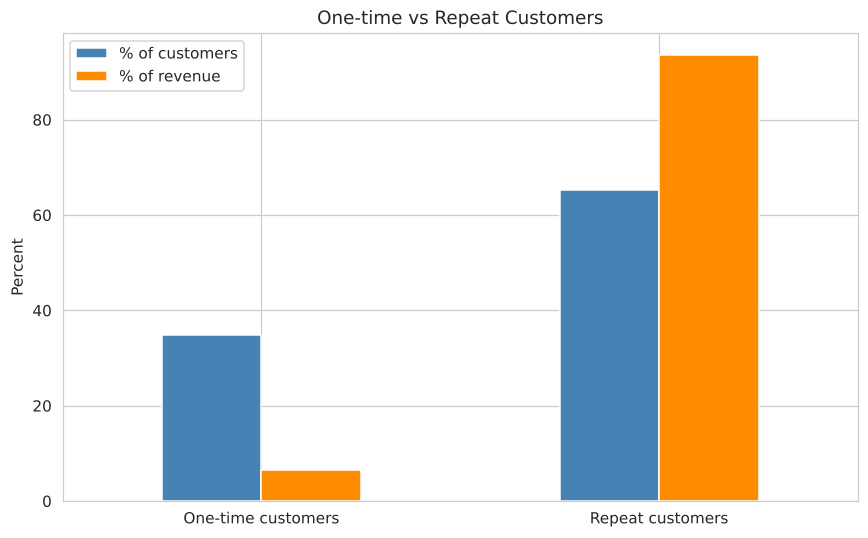

In [55]:
shares = pd.DataFrame({
    "% of customers": [one_time_customer_percent, 100 - one_time_customer_percent],
    "% of revenue": [one_time_revenue_percent, 100 - one_time_revenue_percent]
}, index=["One-time customers", "Repeat customers"])

shares.plot(kind="bar", figsize=(8, 5), color=["steelblue", "darkorange"])
plt.title("One-time vs Repeat Customers")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/10_one_time_vs_repeat.png", dpi=150)
plt.show()

**What the output means:** about **35% of customers bought only once, but they bring only 6.5% of revenue**. Repeat customers are 65% of customers and bring **93.5%** of revenue.

**Business decision:** the shop's money comes from customers who come back. The most valuable action is to turn first-time buyers into second-time buyers, for example with a follow-up email and a small discount on the second order, rather than spending only on finding new customers.

## 3. How many orders does a customer place?

**Business question:** what does the order frequency look like?

In [56]:
orders_count = customers["Orders"].value_counts().sort_index()
orders_count.head(10)

,count
Orders,
1,1505
2,831
3,501
4,395
5,236
6,173
7,139
8,98
9,69


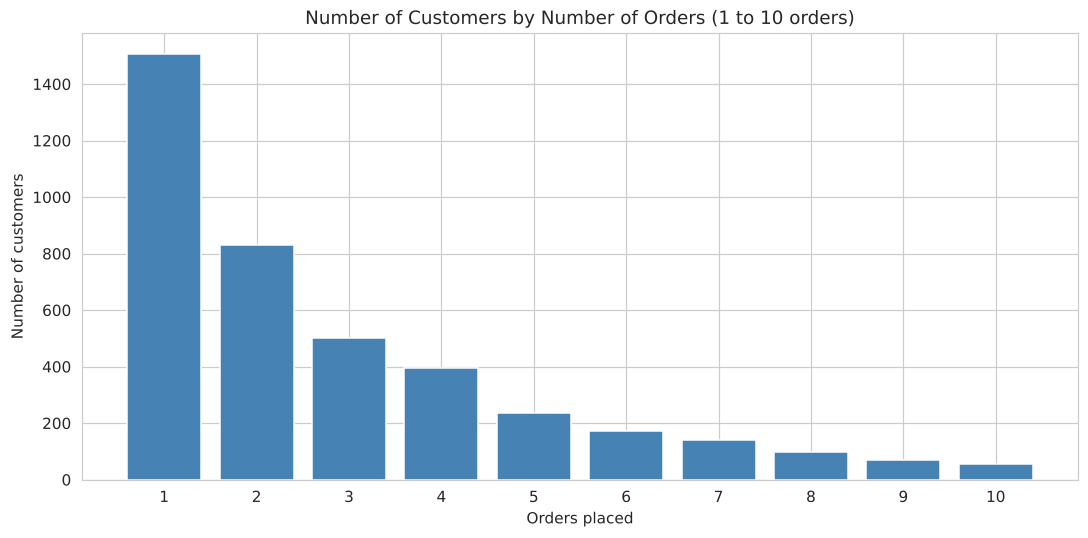

In [57]:
plt.figure(figsize=(10, 5))
plt.bar(orders_count.head(10).index, orders_count.head(10).values, color="steelblue")
plt.title("Number of Customers by Number of Orders (1 to 10 orders)")
plt.xlabel("Orders placed")
plt.ylabel("Number of customers")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.savefig("../images/11_orders_per_customer.png", dpi=150)
plt.show()

In [58]:
loyal = customers[customers["Orders"] >= 10]
print("Customers with 10 or more orders:", len(loyal))
print("Their share of customer revenue (%):", round(loyal["Revenue"].sum() / customers["Revenue"].sum() * 100))

Customers with 10 or more orders: 386
Their share of customer revenue (%): 53


**What the output means:** the bars go down quickly: 1,505 customers ordered once, 831 twice, 501 three times, and so on. A small group of customers order very often: the **386 customers with 10 or more orders** are only about 9% of the customer base but bring about **53% of customer revenue**.

**Business decision:** identify the customers with 10+ orders as the "loyal core" and protect them with good service, early access to new products and reliable stock of the items they order.

## 4. Top customers and dependence on a few customers

**Business question:** how much of the revenue depends on the top customers?

In [59]:
customers_sorted = customers.sort_values("Revenue", ascending=False)
top_10_customers = customers_sorted.head(10)
top_10_customers.round(0)

,Orders,Revenue
CustomerID,,
14646,72,279138.0
18102,60,259657.0
17450,46,194391.0
14911,198,136162.0
12415,20,124565.0
14156,54,116560.0
17511,31,91062.0
16029,62,72708.0
16684,28,66654.0


In [60]:
top_10_share = top_10_customers["Revenue"].sum() / customers["Revenue"].sum() * 100

top_20_percent_count = int(len(customers) * 0.2)
top_20_percent = customers_sorted.head(top_20_percent_count)
top_20_percent_share = top_20_percent["Revenue"].sum() / customers["Revenue"].sum() * 100

print("Top 10 customers' share of customer revenue (%):", round(top_10_share, 1))
print("Top 20% of customers (", top_20_percent_count, "customers ) share of revenue (%):", round(top_20_percent_share, 1))

Top 10 customers' share of customer revenue (%): 16.6
Top 20% of customers ( 866 customers ) share of revenue (%): 73.8


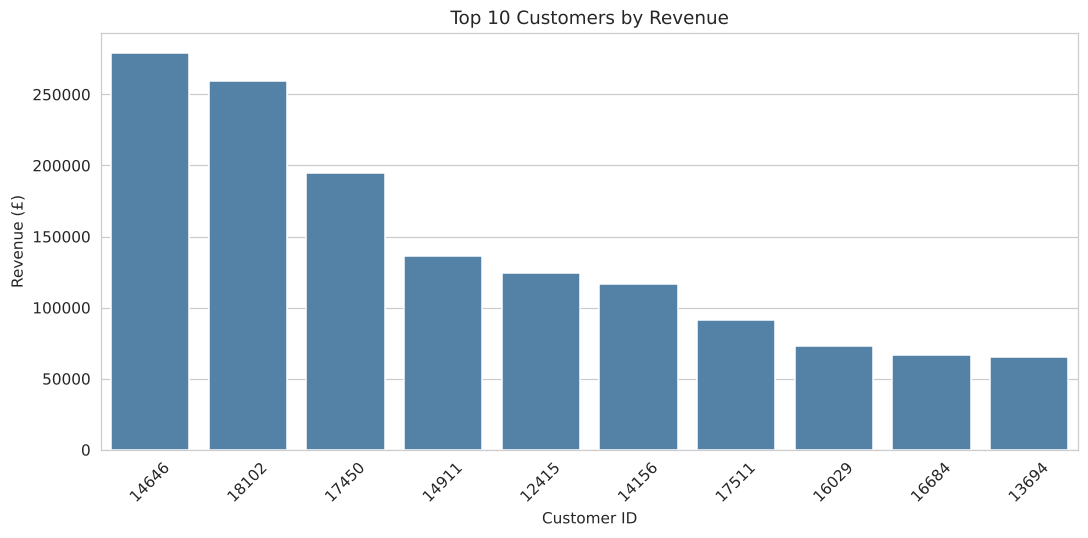

In [61]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_10_customers.index.astype(str), y=top_10_customers["Revenue"], color="steelblue")
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/12_top_customers.png", dpi=150)
plt.show()

**What the output means:** the top 10 customers bring about **17%** of customer revenue, and the top 20% of customers (866 customers) bring about **74%**. The best customer (ID 14646) spent about £279K.

**Business decision:** the business depends heavily on a relatively small group of customers. Give the **top customers a named account manager**, check their stock and delivery needs before every busy season, and watch for any of them reducing their orders, because losing one top customer would be a real loss.

## Key takeaways
1. There are 4,333 identified customers; the **median customer spent £661**, much less than the average of £1,951.
2. About **35% of customers buy only once** and bring just 6.5% of revenue. **Repeat customers bring 93.5%.**
3. The **top 20% of customers bring about 74% of revenue**, and the top 10 alone bring about 17%.
4. Priorities: turn first-time buyers into repeat buyers, and look after the top customers personally.

**Limits:** 15% of revenue has no customer ID, and we only have about 12 months of history.